# 05. 전반기 기대 승률로 후반기를 예측할 수 있을까? (2025 데이터로 재검증)

강의에서는 **2018 MLB** 데이터로 "올스타전 이전 기대 승률이 이전 승률보다 후반기 승률을 조금 더 잘 예측한다"는 결과를 보였다 (상관계수 0.691 vs 0.653).
이 결과가 **2025 MLB**와 **잉글랜드 축구 1~4부 2024-25**에서도 나오는지 직접 확인한다.

- MLB: 2025 올스타전(7월 15일) 기준으로 전반기·후반기를 나눈다.
- 축구: 2025년 1월 1일 기준으로 나눈다 (리그마다 전반기 18~23경기).
- 지수는 k = 2와, **전반기 데이터만으로 찾은 최적 k** 두 가지를 쓴다 (후반기 정보 사용 없음).
- 팀 수가 20~30개로 적어서, 팀을 무작위로 다시 뽑는 **부트스트랩**으로 차이가 우연인지 확인한다.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib import font_manager
from scipy.optimize import minimize_scalar
for f in ["NanumGothic", "Malgun Gothic", "AppleGothic", "Noto Sans CJK JP"]:
    if any(f in x.name for x in font_manager.fontManager.ttflist):
        plt.rcParams["font.family"] = f; break
plt.rcParams["axes.unicode_minus"] = False

def team_games(df, home, away, hs, as_, date, dayfirst=False):
    """경기 기록을 '팀별 경기' 형태로 펼친다 (홈 경기 + 원정 경기)."""
    h = pd.DataFrame({"team": df[home], "F": df[hs], "A": df[as_], "date": df[date]})
    a = pd.DataFrame({"team": df[away], "F": df[as_], "A": df[hs], "date": df[date]})
    g = pd.concat([h, a], ignore_index=True)
    g["date"] = pd.to_datetime(g["date"], dayfirst=dayfirst)
    return g

def season_table(g):
    """팀별 경기 수, 승률, 득점, 실점"""
    return g.groupby("team").agg(G=("res", "size"), wpc=("res", "mean"), F=("F", "sum"), A=("A", "sum"))

def pyth(F, A, k=2.0):
    return F**k / (F**k + A**k)

def best_k(t):
    """실제 승률과의 제곱오차가 가장 작은 지수 k"""
    return minimize_scalar(lambda k: ((t.wpc - pyth(t.F, t.A, k))**2).mean(), bounds=(0.5, 30), method="bounded").x

# 데이터 불러오기
mlb = pd.read_excel("../data/mlb-2025-asplayed.xlsx", sheet_name="As-Played Schedule")
MG = team_games(mlb, "Home", "Away", "Home Score", "Away Score", "Date")
MG["res"] = (MG.F > MG.A).astype(float)                       # 야구: 승 1, 패 0

eng = pd.read_excel("../data/epl-2025-asplayed.xlsx")
EG = team_games(eng, "HomeTeam", "AwayTeam", "FTHG", "FTAG", "Date", dayfirst=True)
EG["div"] = pd.concat([eng.Div, eng.Div], ignore_index=True)
EG["res"] = np.where(EG.F > EG.A, 1, np.where(EG.F == EG.A, 1/3, 0))   # 축구: 승점 비율 (승 3, 무 1)

nba = pd.read_excel("../data/nba-2025-asplayed.xlsx")
NBA = pd.DataFrame({"G": 82, "wpc": nba.Wins / 82, "F": nba.Points_For, "A": nba.Points_Against}).set_index(nba.Team)
MLB, ENG = season_table(MG), season_table(EG)
print(f"MLB {len(MLB)}팀 {len(mlb)}경기 | NBA {len(NBA)}팀 | 잉글랜드 1~4부 {len(ENG)}팀 {len(eng)}경기")

MLB 30팀 2430경기 | NBA 30팀 | 잉글랜드 1~4부 92팀 2036경기


In [2]:
def split_test(g, cut, label, n_boot=5000, seed=0):
    h1, h2 = season_table(g[g.date < cut]), season_table(g[g.date > cut])
    d = h1.join(h2, lsuffix="1", rsuffix="2").dropna()
    k1 = best_k(pd.DataFrame({"wpc": d.wpc1, "F": d.F1, "A": d.A1}))     # 전반기만으로 추정
    d["pyth1_k2"], d["pyth1_kopt"] = pyth(d.F1, d.A1, 2), pyth(d.F1, d.A1, k1)
    r = {c: d.wpc2.corr(d[c]) for c in ["wpc1", "pyth1_k2", "pyth1_kopt"]}
    # 부트스트랩: (기대 승률 상관) - (전반기 승률 상관) > 0 인 비율
    rng = np.random.default_rng(seed); wins = 0
    for _ in range(n_boot):
        s = d.iloc[rng.integers(0, len(d), len(d))]
        wins += s.wpc2.corr(s.pyth1_kopt) > s.wpc2.corr(s.wpc1)
    return {"리그": label, "팀 수": len(d), "전반기 경기": round(d.G1.mean()), "후반기 경기": round(d.G2.mean()),
            "전반기 승률": r["wpc1"], "기대 승률 (k=2)": r["pyth1_k2"], f"기대 승률 (최적 k)": r["pyth1_kopt"],
            "최적 k": k1, "기대 승률이 나을 확률": wins / n_boot}

rows = [split_test(MG, pd.Timestamp("2025-07-15"), "MLB 2025")]
rows.append(split_test(EG, pd.Timestamp("2025-01-01"), "잉글랜드 1~4부 전체"))
for dv, nm in [("E0", "프리미어리그"), ("E1", "챔피언십 (2부)"), ("E2", "리그1 (3부)"), ("E3", "리그2 (4부)")]:
    rows.append(split_test(EG[EG["div"] == dv], pd.Timestamp("2025-01-01"), nm))
tab = pd.DataFrame(rows).set_index("리그")
print("값: 후반기 승률과의 상관계수")
tab.style.format({"전반기 승률": "{:.3f}", "기대 승률 (k=2)": "{:.3f}", "기대 승률 (최적 k)": "{:.3f}", "최적 k": "{:.2f}", "기대 승률이 나을 확률": "{:.0%}"})

값: 후반기 승률과의 상관계수


,팀 수,전반기 경기,후반기 경기,전반기 승률,기대 승률 (k=2),기대 승률 (최적 k),최적 k,기대 승률이 나을 확률
리그,,,,,,,,
MLB 2025,30,96,66,0.454,0.421,0.423,1.70,35%
잉글랜드 1~4부 전체,92,22,22,0.557,0.565,0.578,1.21,72%
프리미어리그,20,19,19,0.724,0.646,0.659,1.34,25%
챔피언십 (2부),24,24,21,0.593,0.649,0.685,1.02,95%
리그1 (3부),24,22,23,0.532,0.599,0.599,1.34,92%
리그2 (4부),24,22,23,0.237,0.293,0.288,1.12,73%


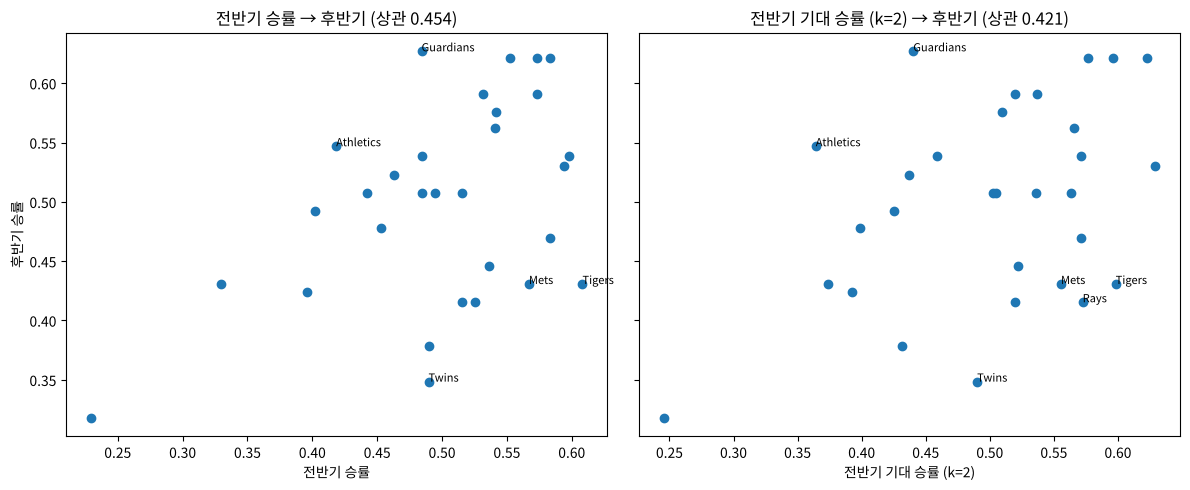

In [3]:
# MLB 2025: 전반기 승률 vs 기대 승률로 본 후반기
h1, h2 = season_table(MG[MG.date < "2025-07-15"]), season_table(MG[MG.date > "2025-07-15"])
d = h1.join(h2, lsuffix="1", rsuffix="2")
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, (x, lab) in zip(axes, [(d.wpc1, "전반기 승률"), (pyth(d.F1, d.A1, 2), "전반기 기대 승률 (k=2)")]):
    ax.scatter(x, d.wpc2)
    for t in d.index:
        if abs(d.loc[t, "wpc2"] - x[t]) > 0.12:
            ax.annotate(t.split()[-1], (x[t], d.loc[t, "wpc2"]), fontsize=8)
    ax.set_xlabel(lab); ax.set_title(f"{lab} → 후반기 (상관 {d.wpc2.corr(x):.3f})")
axes[0].set_ylabel("후반기 승률"); plt.tight_layout(); plt.show()

## 결과

- **2025 MLB에서는 강의 결과가 재현되지 않았다.** 후반기 승률과의 상관이 전반기 승률 0.454, 기대 승률 0.42 정도로 오히려 전반기 승률이 조금 높았다. 2018년(0.65~0.69)보다 두 값 모두 크게 낮아, 2025 시즌은 전반기와 후반기 성적이 덜 이어진 시즌이었다.
- **잉글랜드 축구는 리그마다 달랐다.** 2부·3부·4부에서는 기대 승률이 더 나았고, 프리미어리그에서는 전반기 승률이 더 나았다. 92개 팀 전체로는 기대 승률이 근소하게 앞섰다.
- **결과가 리그마다 반대로 나왔다.** 부트스트랩으로 '기대 승률이 더 나을 확률'을 보면 챔피언십(95%)·리그1(92%)에서는 비교적 뚜렷했지만, MLB(35%)와 프리미어리그(25%)에서는 오히려 전반기 승률 쪽이 나았다. 팀 수가 20~30개라 상관계수 0.03 정도의 차이는 표본이 조금만 바뀌어도 뒤집힐 수 있다.

**정리**: "기대 승률이 실제 승률보다 미래를 더 잘 예측한다"는 강의의 결론은 **2025 데이터에서는 일관되게 나타나지 않았다.** 한 시즌, 한 리그의 결과만으로 일반화하기 어렵다는 것을 직접 확인한 셈이다. 여러 시즌을 모아 검증하면 더 확실한 답을 얻을 수 있다.